<a href="https://colab.research.google.com/github/RaghavVerma01/CSET343-Lab/blob/main/Lab_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip install -U scikit-learn scikeras

In [2]:

%pip install -q pandas numpy scikit-learn tensorflow scikeras matplotlib

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_auc_score
)
from scikeras.wrappers import KerasClassifier
from tensorflow import keras
from tensorflow.keras import layers

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
keras.utils.set_random_seed(RANDOM_STATE)


In [3]:
# Pima Indians Diabetes dataset (768 rows, 8 predictors, 1 binary target)
DATA_URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

columns = [
    "Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
    "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"
]

df = pd.read_csv(DATA_URL, header=None, names=columns)
print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [4]:
display(df.info())
display(df.describe().T)
print("\\nMissing values per column:")
display(df.isnull().sum())
print("\\nTarget distribution:")
display(df["Outcome"].value_counts().rename(index={0: "No diabetes", 1: "Diabetes"}))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


None

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


\nMissing values per column:


,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


\nTarget distribution:


,count
Outcome,
No diabetes,500
Diabetes,268


In [5]:
df_clean = df.copy()

zero_as_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
df_clean[zero_as_missing] = df_clean[zero_as_missing].replace(0, np.nan)

X = df_clean.drop(columns="Outcome")
y = df_clean["Outcome"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Training features:", X_train.shape)
print("Test features:", X_test.shape)
print("Training target distribution:")
display(y_train.value_counts(normalize=True).rename("proportion"))


Training features: (614, 8)
Test features: (154, 8)
Training target distribution:


,proportion
Outcome,
0,0.651466
1,0.348534


In [6]:
def build_model(meta, hidden_neurons=16, activation="relu",
                dropout_rate=0.0, initializer="glorot_uniform",
                learning_rate=0.001):
    # SciKeras provides `meta`, including the number of input features.
    model = keras.Sequential([
        keras.Input(shape=(meta["n_features_in_"],)),
        layers.Dense(
            hidden_neurons,
            activation=activation,
            kernel_initializer=initializer
        ),
        layers.Dropout(dropout_rate),
        layers.Dense(1, activation="sigmoid")
    ])

    optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
    model.compile(
        optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model


In [7]:
from sklearn.impute import SimpleImputer

pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("nn", KerasClassifier(
        model=build_model,
        verbose=0,
        random_state=RANDOM_STATE
    ))
])

param_grid = {
    "nn__model__hidden_neurons": [8, 16],
    "nn__model__activation": ["relu", "tanh"],
    "nn__model__dropout_rate": [0.0, 0.2],
    "nn__model__initializer": ["glorot_uniform", "he_uniform"],
    "nn__model__learning_rate": [0.001, 0.01],
    "nn__batch_size": [16, 32],
    "nn__epochs": [20]
}

grid = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="accuracy",
    cv=2,
    n_jobs=1,          # safer for TensorFlow; parallel workers can exhaust memory
    refit=True,
    verbose=2,
    return_train_score=True
)

print("Total parameter combinations:", int(np.prod([len(v) for v in param_grid.values()])))
print("Total CV fits:", int(np.prod([len(v) for v in param_grid.values()])) * 3)


Total parameter combinations: 64
Total CV fits: 192


In [8]:
grid.fit(X_train, y_train)

print("Best cross-validation accuracy:", round(grid.best_score_, 4))
print("Best parameters:")
for key, value in grid.best_params_.items():
    print(f"  {key}: {value}")


Fitting 2 folds for each of 64 candidates, totalling 128 fits
[CV] END nn__batch_size=16, nn__epochs=20, nn__model__activation=relu, nn__model__dropout_rate=0.0, nn__model__hidden_neurons=8, nn__model__initializer=glorot_uniform, nn__model__learning_rate=0.001; total time=   9.1s
[CV] END nn__batch_size=16, nn__epochs=20, nn__model__activation=relu, nn__model__dropout_rate=0.0, nn__model__hidden_neurons=8, nn__model__initializer=glorot_uniform, nn__model__learning_rate=0.001; total time=   3.5s
[CV] END nn__batch_size=16, nn__epochs=20, nn__model__activation=relu, nn__model__dropout_rate=0.0, nn__model__hidden_neurons=8, nn__model__initializer=glorot_uniform, nn__model__learning_rate=0.01; total time=   3.8s
[CV] END nn__batch_size=16, nn__epochs=20, nn__model__activation=relu, nn__model__dropout_rate=0.0, nn__model__hidden_neurons=8, nn__model__initializer=glorot_uniform, nn__model__learning_rate=0.01; total time=   3.5s
[CV] END nn__batch_size=16, nn__epochs=20, nn__model__activation

In [17]:
results = pd.DataFrame(grid.cv_results_).sort_values("rank_test_score")
result_columns = [
    "rank_test_score", "mean_test_score", "std_test_score",
    "mean_train_score", "mean_fit_time", "params"
]
display(results[result_columns].head(10).reset_index(drop=True))


,rank_test_score,mean_test_score,std_test_score,mean_train_score,mean_fit_time,params
0,1,NaN,NaN,NaN,3.338497,"{'nn__batch_size': 16, 'nn__epochs': 20, 'nn__..."
1,1,NaN,NaN,NaN,3.349306,"{'nn__batch_size': 16, 'nn__epochs': 20, 'nn__..."
2,1,NaN,NaN,NaN,3.321194,"{'nn__batch_size': 16, 'nn__epochs': 20, 'nn__..."
3,1,NaN,NaN,NaN,3.326498,"{'nn__batch_size': 16, 'nn__epochs': 20, 'nn__..."
4,1,NaN,NaN,NaN,3.348663,"{'nn__batch_size': 16, 'nn__epochs': 20, 'nn__..."
5,1,NaN,NaN,NaN,3.296235,"{'nn__batch_size': 16, 'nn__epochs': 20, 'nn__..."
6,1,NaN,NaN,NaN,3.296672,"{'nn__batch_size': 16, 'nn__epochs': 20, 'nn__..."
7,1,NaN,NaN,NaN,3.235632,"{'nn__batch_size': 16, 'nn__epochs': 20, 'nn__..."
8,1,NaN,NaN,NaN,3.528779,"{'nn__batch_size': 16, 'nn__epochs': 20, 'nn__..."
9,1,NaN,NaN,NaN,3.455953,"{'nn__batch_size': 16, 'nn__epochs': 20, 'nn__..."


Test accuracy: 0.7468
\nClassification report:
              precision    recall  f1-score   support

 No diabetes       0.79      0.83      0.81       100
    Diabetes       0.65      0.59      0.62        54

    accuracy                           0.75       154
   macro avg       0.72      0.71      0.72       154
weighted avg       0.74      0.75      0.74       154



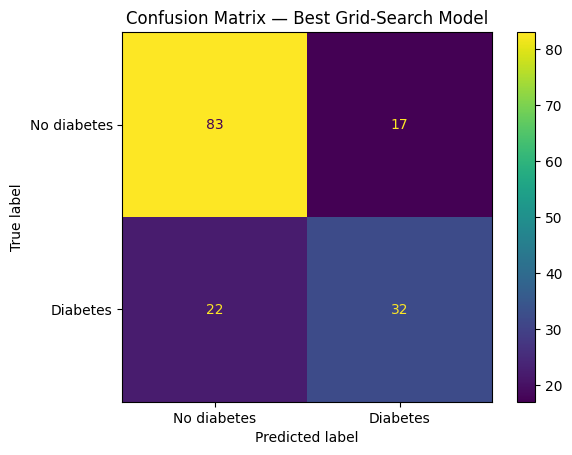

Test ROC-AUC: 0.8224


In [9]:
best_model = grid.best_estimator_
y_pred = best_model.predict(X_test).astype(int)

print("Test accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["No diabetes", "Diabetes"], zero_division=0))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No diabetes", "Diabetes"]).plot()
plt.title("Confusion Matrix — Best Grid-Search Model")
plt.show()

try:
    y_prob = best_model.predict_proba(X_test)[:, 1]
    print("Test ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))
except (AttributeError, IndexError, ValueError):
    print("ROC-AUC could not be calculated for this estimator.")
